In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
import streamlit as st

print("All libraries installed successfully!")


All libraries installed successfully!


In [3]:

import pandas as pd

# Creating an improved sample dataset
data = {
    "text": [
        # Positive reviews
        "I love this product",
        "This product is amazing",
        "I am very happy with this purchase",
        "The service is excellent",
        "I really like it",
        "What a wonderful experience",
        "This product is fantastic",
        "I am completely satisfied",
        "Very good quality",
        "I enjoyed this a lot",
        "The product works perfectly",
        "The delivery was excellent",
        "I highly recommend this product",
        "The quality is outstanding",
        "I am pleased with the results",
        "Excellent customer support",
        "This is worth every penny",
        "The product exceeded my expectations",
        "Very helpful and reliable service",
        "I would buy this again",

        # Negative reviews
        "I hate this product",
        "This product is terrible",
        "I am very disappointed",
        "The service is awful",
        "I really dislike it",
        "What a horrible experience",
        "This is the worst product",
        "I am unhappy with my purchase",
        "Very poor quality",
        "I regret buying this",
        "The product stopped working",
        "The delivery was very late",
        "I would not recommend this",
        "The quality is disappointing",
        "Customer support was unhelpful",
        "This product is a waste of money",
        "The product is broken",
        "The service was terrible",
        "I received a damaged item",
        "I am not satisfied at all",

        # Neutral reviews
        "The product is okay",
        "It is an average product",
        "Nothing special",
        "The service was normal",
        "It is neither good nor bad",
        "The experience was ordinary",
        "I have no strong opinion",
        "It works as expected",
        "The product is acceptable",
        "It is just fine",
        "The product arrived yesterday",
        "The package contains two items",
        "The product is available in blue",
        "The delivery happened today",
        "This is a mobile phone",
        "The box contains a charger",
        "I ordered this product online",
        "The product has three buttons",
        "The item weighs one kilogram",
        "The product comes with a manual"
    ],

    "sentiment": (
        ["Positive"] * 20 +
        ["Negative"] * 20 +
        ["Neutral"] * 20
    )
}

df = pd.DataFrame(data)

print("Dataset Shape:", df.shape)
print("\nSentiment Counts:")
print(df["sentiment"].value_counts())

df.head()


Dataset Shape: (60, 2)

Sentiment Counts:
sentiment
Positive    20
Negative    20
Neutral     20
Name: count, dtype: int64


,text,sentiment
0,I love this product,Positive
1,This product is amazing,Positive
2,I am very happy with this purchase,Positive
3,The service is excellent,Positive
4,I really like it,Positive


In [14]:
# Check dataset size
print("Dataset shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check sentiment distribution
print("\nSentiment counts:")
print(df["sentiment"].value_counts())

Dataset shape: (60, 2)

Missing values:
text         0
sentiment    0
dtype: int64

Sentiment counts:
sentiment
Positive    20
Negative    20
Neutral     20
Name: count, dtype: int64


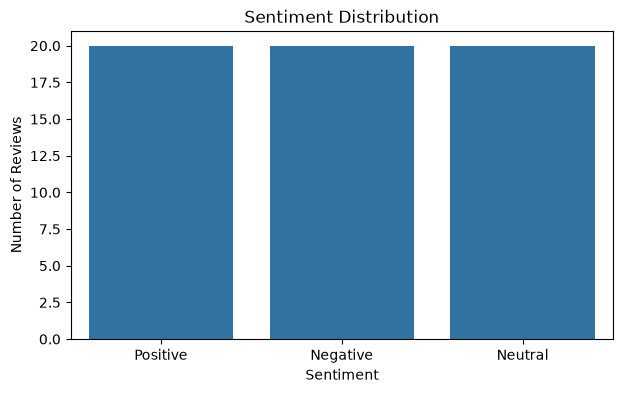

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="sentiment")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [24]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split text and sentiment labels
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"],
    df["sentiment"],
    test_size=0.2,
    random_state=42,
    stratify=df["sentiment"]
)

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer()

# Learn vocabulary from training data
X_train = tfidf.fit_transform(X_train_text)

# Transform testing data using the same vocabulary
X_test = tfidf.transform(X_test_text)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (48, 101)
Testing data shape: (12, 101)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 48
Testing samples: 12


In [25]:

from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000)

# Train the model using training data
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [26]:
from sklearn.metrics import accuracy_score, classification_report

# Predict sentiments for test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 50.0 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.33      0.25      0.29         4
     Neutral       0.67      1.00      0.80         4
    Positive       0.33      0.25      0.29         4

    accuracy                           0.50        12
   macro avg       0.44      0.50      0.46        12
weighted avg       0.44      0.50      0.46        12



In [21]:
def predict_sentiment(text):
    text_tfidf = tfidf.transform([text])
    prediction = model.predict(text_tfidf)[0]
    probability = model.predict_proba(text_tfidf)[0].max()

    print("Input Text:", text)
    print("Predicted Sentiment:", prediction)
    print("Model Confidence:", round(probability * 100, 2), "%")


predict_sentiment("I really love this product")

Input Text: I really love this product
Predicted Sentiment: Positive
Model Confidence: 51.08 %


In [22]:
predict_sentiment("This product is terrible")
predict_sentiment("The product is okay")
predict_sentiment("I am very happy")

Input Text: This product is terrible
Predicted Sentiment: Negative
Model Confidence: 52.95 %
Input Text: The product is okay
Predicted Sentiment: Neutral
Model Confidence: 40.08 %
Input Text: I am very happy
Predicted Sentiment: Positive
Model Confidence: 43.76 %


In [23]:
import joblib

# Save the trained model
joblib.dump(model, "sentiment_model.pkl")

# Save the TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
